# 6 · Segmentation snippets: paw, whisk, lick + wheel, and how paw and wheel states map

Example 25 s snippets from proficient cohort sessions, all at 60 Hz:
- **wheel velocity** (rad/s) and **paw speed** (left / right paw, px/s, from the design-matrix positions; dashed blue = stimulus, red = feedback)
- **wheel** states: the absolute-velocity fit (`5b_proficient_shapes_fit_absolute`), each IBL movement coloured by its cluster (hue = stimulus side reported, **teal left / orange right** / grey both; lightness = vigor; hatch = jitter). White = not in a movement. The wheel has its own hue pair (not the paw's violet / amber, and no blue or red, which are LD1's).
- **paw**, **whisk**, **lick**: the existing proficient states (`data/states_files`, decoded with `paper_style`, uniform paw-state set). In the paw palette violet / amber mean which **paw** leads, not a stimulus side.

Wheel labels come from the saved global fit and are computed here, in memory, for the sessions used.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from joblib import Parallel, delayed
import proficient_movements as pm, primitives as pr
import sys; sys.path.insert(0, str(pm.PI))
import paper_style as ps
ps.use('paper', dpi=110); ps.use_paw_states('uniform')

MODEL = pm.load_model('absolute')
K, WDESC = MODEL['K'], MODEL['desc']
# WHEEL PALETTE: same rule as the paw states (lightness = vigor rank, hue = side, chroma = how one-sided) but its own
# hue pair, because wheel and paw are different things: teal (cold) = reports LEFT, orange (warm) = reports RIGHT.
# Dataviz palette validator at L 0.65: teal 195 vs orange 45 pass (protan dE 15.2, normal 25.2). But orange vs the
# paw's amber (hue 64) FAILS (deutan 2.3, normal 4.9) and vs LD1's red (22) fails too (deutan 4.8, normal 6.1):
# orange only works with wheel and paw in separate, labelled rows. Alternative: olive (120), teal vs olive pass
# (deutan 15.4, normal 16.1) and olive vs amber normal 14.0 -- shown in the legend for comparison.
WHEEL_HUES = (195, 45)
ALT_HUES = (195, 120)
# chroma scaled by 0.55: at full chroma pale teal and lime turn neon (the paw's violet / amber stay muted at the same chroma)
WCOL = ps.state_palette(np.log(WDESC.peak_rad_s.values), gap=-0.55 * WDESC.side_index.values, hues=WHEEL_HUES)
ALT_WCOL = ps.state_palette(np.log(WDESC.peak_rad_s.values), gap=-0.55 * WDESC.side_index.values, hues=ALT_HUES)
OLD_WCOL = MODEL['COL']
SF = pm.PI / 'data' / 'states_files'
coh = pm.cohort()
WIN = 25

def load(mouse, eid):
    """states-file frames with paw / whisk / lick, paw speeds and the wheel cluster of each frame (-1 = still)."""
    st = pd.read_parquet(SF / f'8_states_file_{eid}_{mouse}',
                         columns=['Bin', 'most_likely_states', 'l_paw_x', 'l_paw_y', 'r_paw_x', 'r_paw_y'])
    st['paw'], st['whisk'], st['lick'] = ps.decode_syllables(ps.paw_codes(st.most_likely_states.values))
    dt = np.gradient(st.Bin.values)
    for p in ('l', 'r'):
        st[f'{p}_speed'] = np.hypot(np.gradient(st[f'{p}_paw_x'].values), np.gradient(st[f'{p}_paw_y'].values)) / dt
    t, vel, frame, tr = pm.session_labels(MODEL, eid, mouse)
    i = np.clip(np.searchsorted(t, st.Bin.values), 0, len(t) - 1)
    ok = np.abs(t[i] - st.Bin.values) < 1 / 120
    st['wheel'] = np.where(ok, frame[i], -1)
    st['wheel_vel'] = np.where(ok, vel[i], np.nan)
    st['mouse'], st['eid'] = mouse, eid
    return st, tr

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Snippets

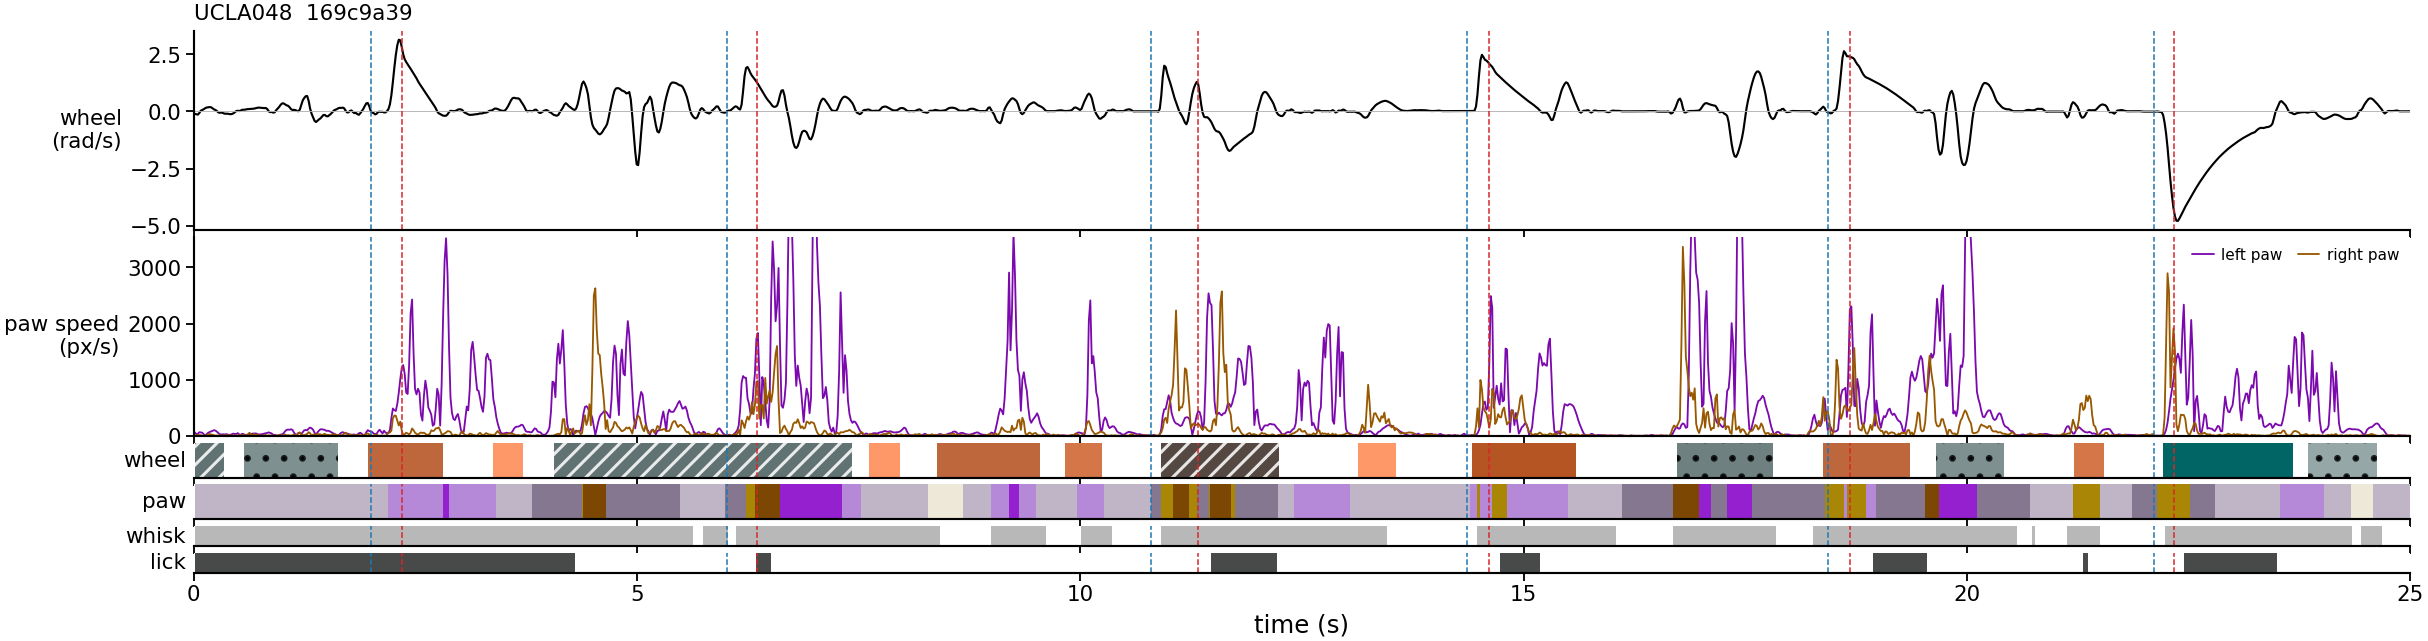

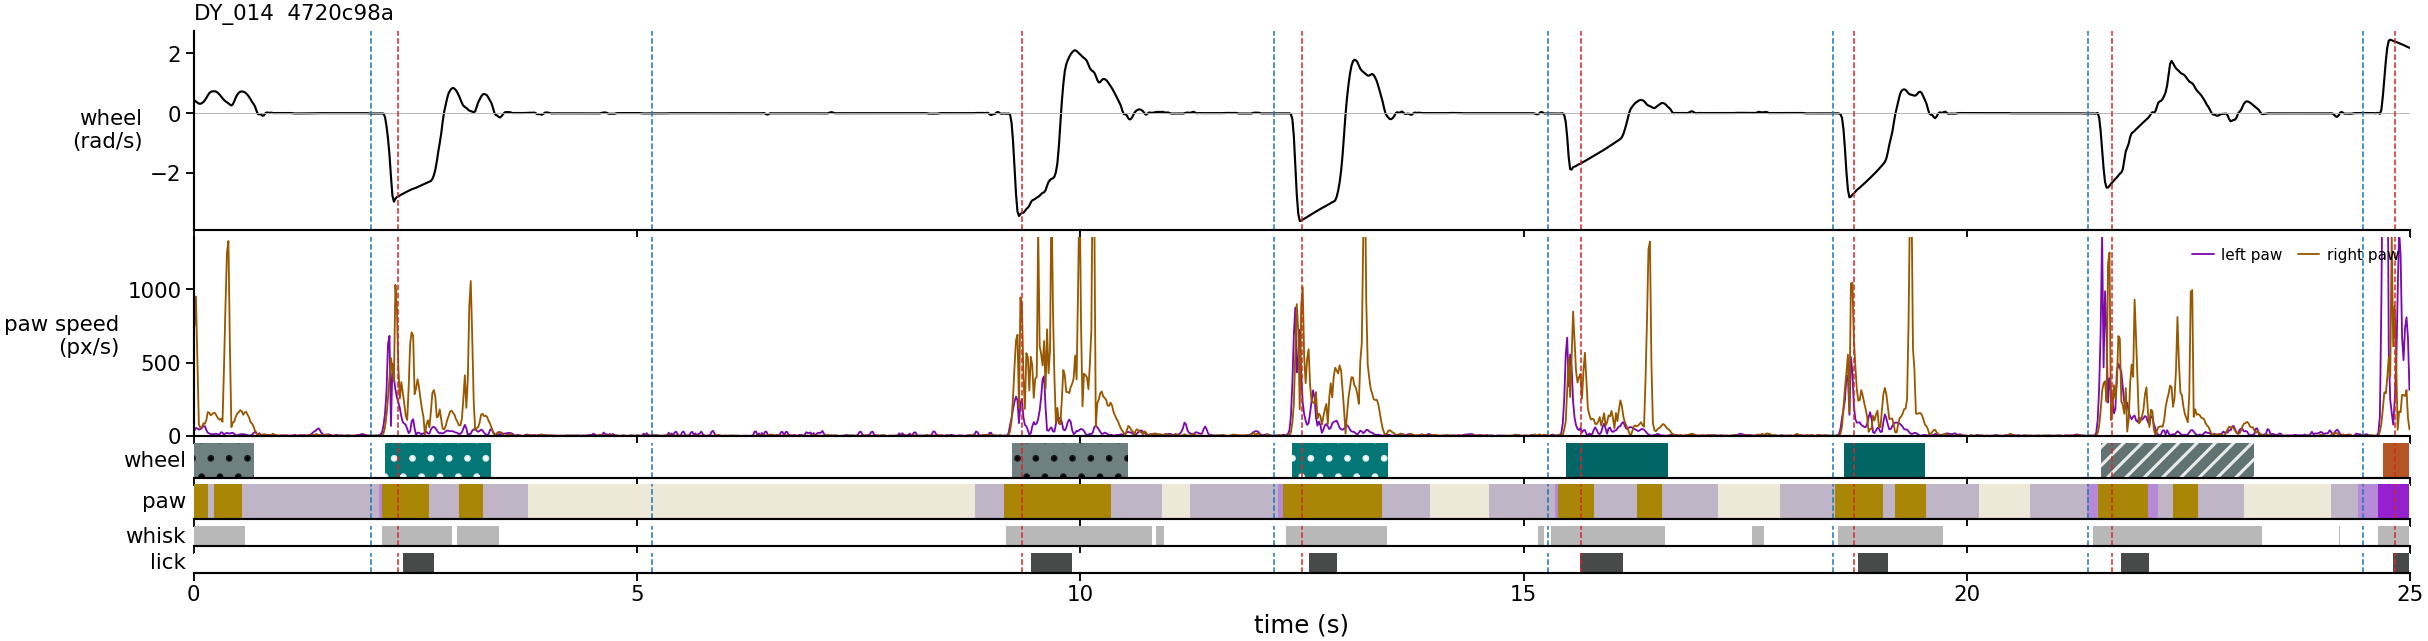

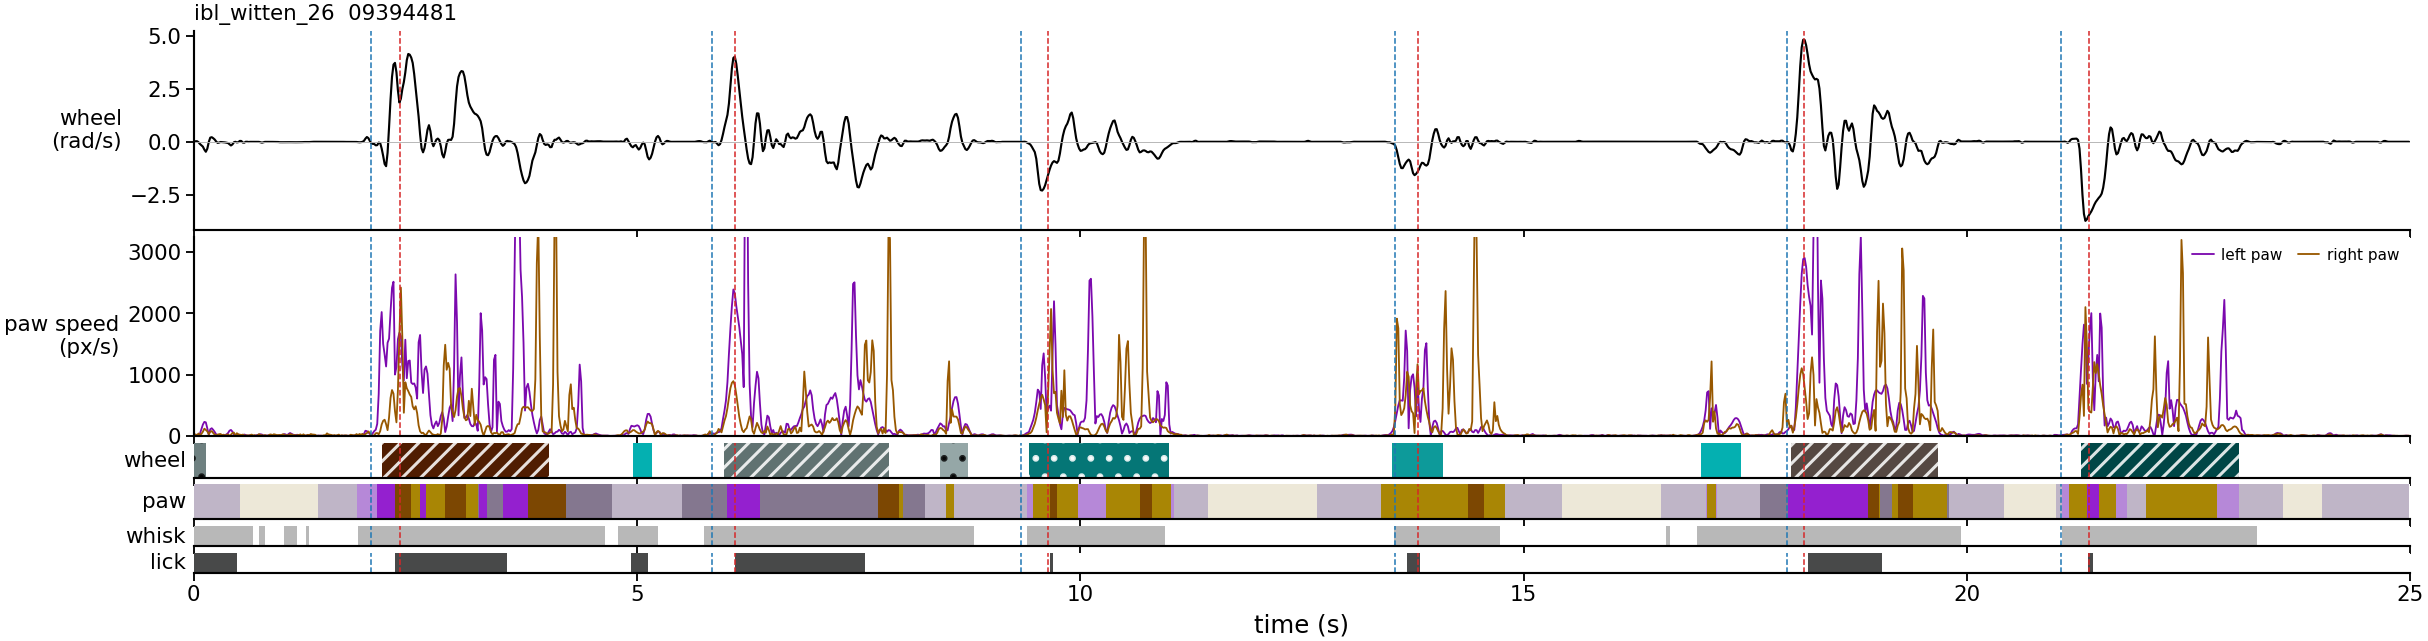

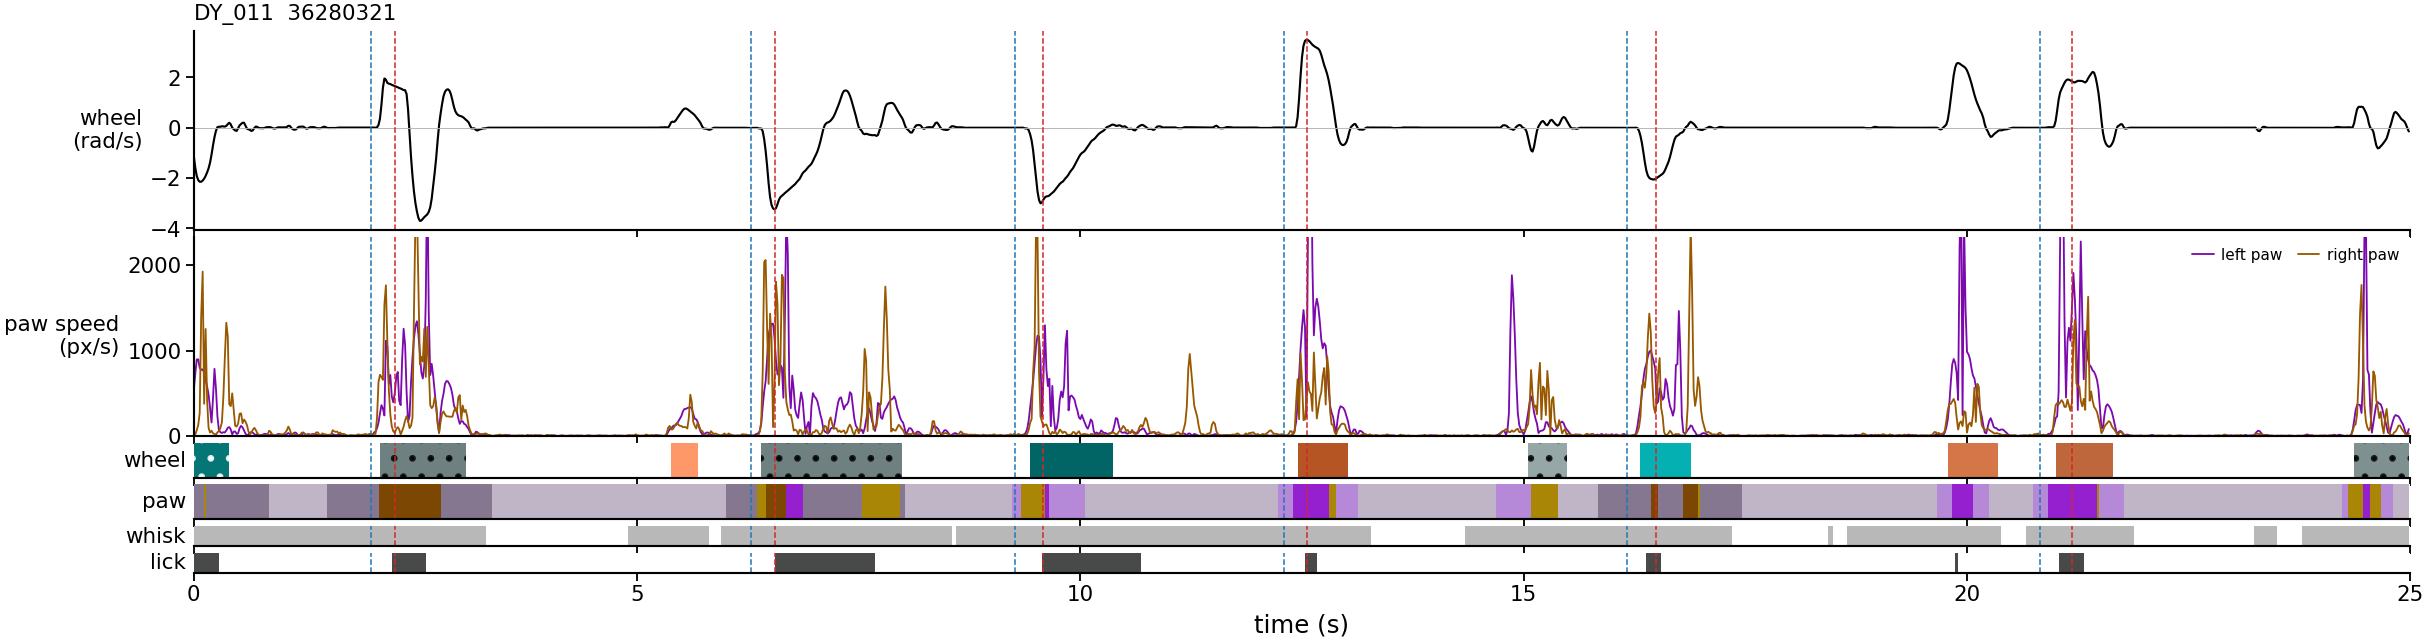

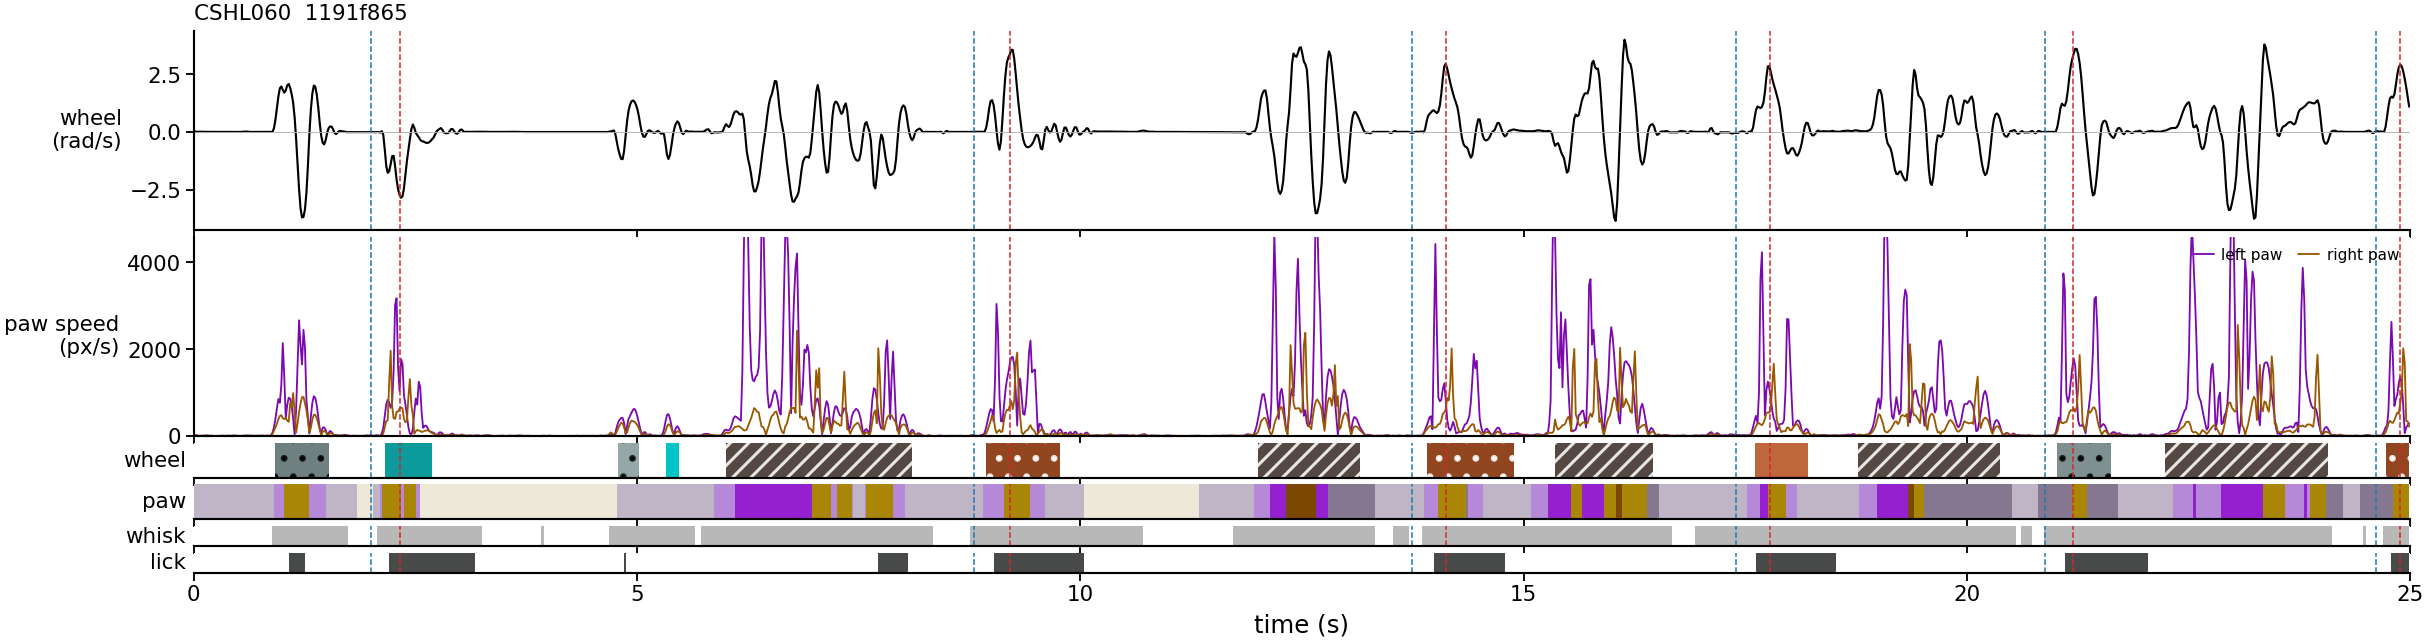

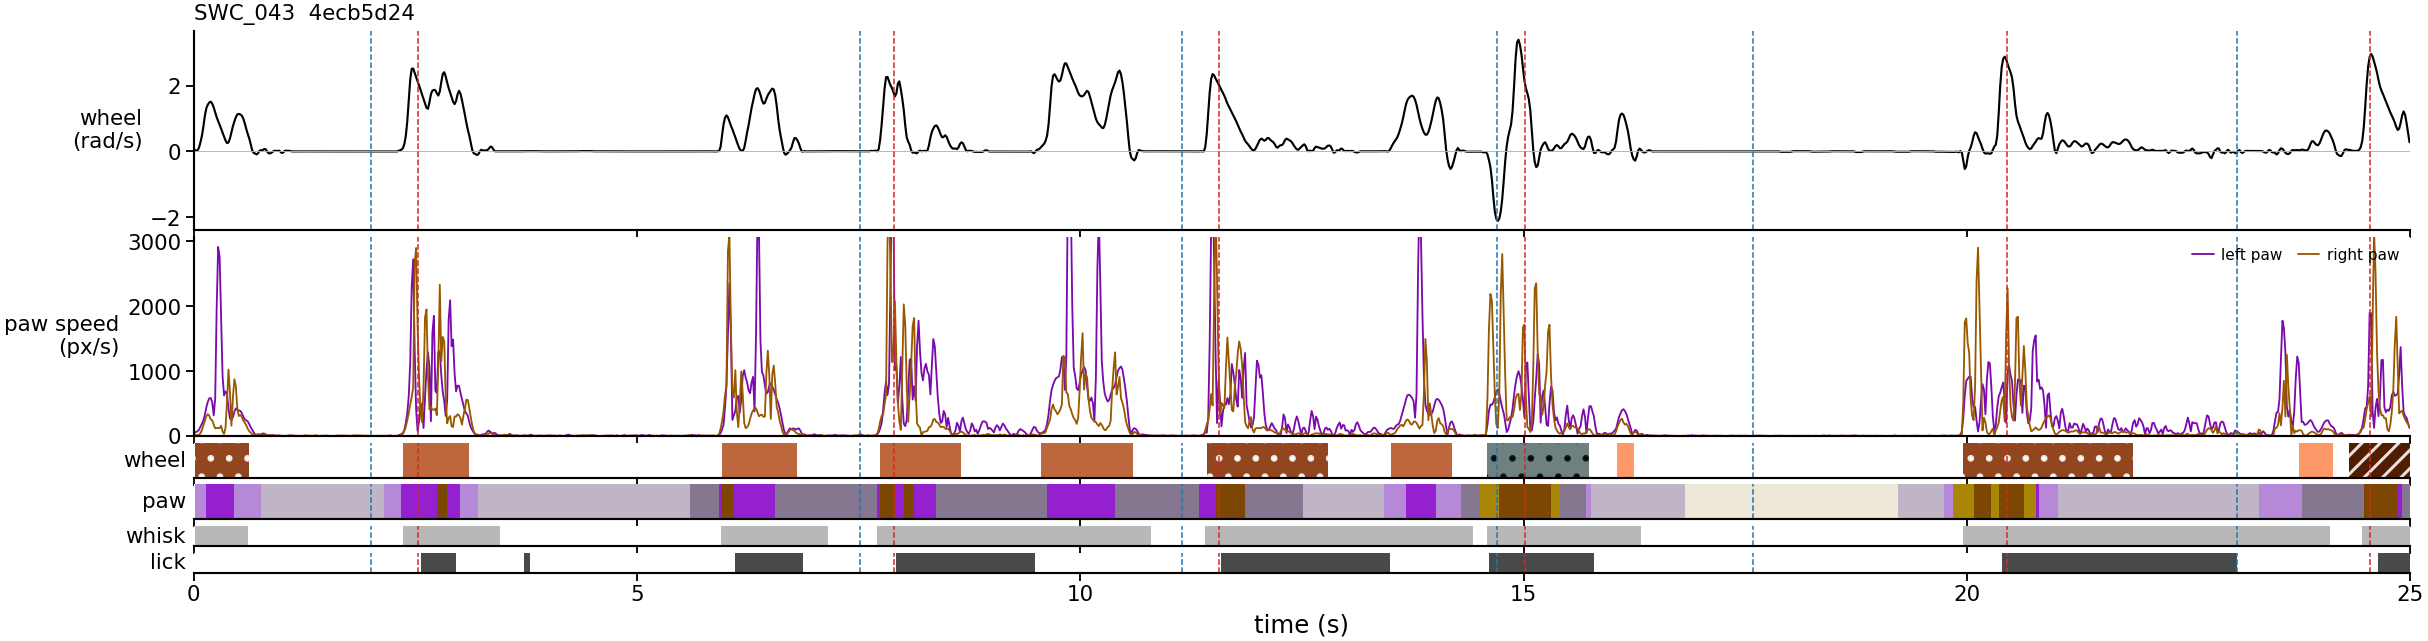

In [2]:
def strip(ax, x, f, colours, hatch=None, label=None):
    """Contiguous runs of f as coloured rectangles (f < 0 or NaN = blank)."""
    f = np.asarray(f, float)
    edges = np.flatnonzero(np.diff(np.r_[np.nan, f, np.nan]) != 0)
    edges = np.r_[0, np.flatnonzero(np.r_[True, f[1:] != f[:-1]])[1:], len(f)]
    for a, b in zip(edges[:-1], edges[1:]):
        c = f[a]
        if not np.isfinite(c) or c < 0: continue
        col = colours[int(c)]
        ax.add_patch(Rectangle((x[a], 0), x[min(b, len(x) - 1)] - x[a], 1, facecolor=col, lw=0,
                               hatch=hatch[int(c)] if hatch else None, edgecolor=ps.hatch_ink(col)))
    ax.set_ylim(0, 1); ax.set_yticks([]); ax.set_ylabel(label, rotation=0, ha='right', va='center', fontsize=7)
    for sp in ('top', 'right', 'left'): ax.spines[sp].set_visible(False)

WH = [MODEL['HATCH'][WDESC.jitter[c]] for c in range(K)]
def snippet(mouse, eid, frac=.45, win=WIN):
    st, tr = load(mouse, eid)
    stim = pr.stim_times(tr)
    t0 = stim.iloc[int(frac * len(tr))] - 2
    s = st[(st.Bin >= t0) & (st.Bin < t0 + win)]
    x = s.Bin.values - t0
    fig, axs = plt.subplots(6, 1, figsize=(13, 3.2), sharex=True,
                            gridspec_kw=dict(height_ratios=[2, 2, .35, .35, .2, .2], hspace=.08))
    axs[0].plot(x, s.wheel_vel, c='k', lw=.7); axs[0].axhline(0, c='0.7', lw=.3)
    axs[0].set_ylabel('wheel\n(rad/s)', rotation=0, ha='right', va='center', fontsize=7)
    axs[1].plot(x, s.l_speed, c=ps.PAW_LEFT, lw=.6, label='left paw'); axs[1].plot(x, s.r_speed, c=ps.PAW_RIGHT, lw=.6, label='right paw')
    axs[1].set_ylim(0, np.nanpercentile(np.r_[s.l_speed, s.r_speed], 99.5)); axs[1].legend(fontsize=5, loc='upper right', ncol=2, frameon=False)
    axs[1].set_ylabel('paw speed\n(px/s)', rotation=0, ha='right', va='center', fontsize=7)
    strip(axs[2], x, s.wheel, WCOL, WH, 'wheel')
    strip(axs[3], x, s.paw, ps.PAW_STATE_COLORS, label='paw')
    strip(axs[4], x, s.whisk.where(s.whisk == 1, -1), {1: ps.SYLLABLE['Whisk']}, label='whisk')
    strip(axs[5], x, s.lick.where(s.lick == 1, -1), {1: ps.SYLLABLE['Lick']}, label='lick')
    for ev, col in [(stim.values, 'tab:blue'), (tr.feedback_times.values, 'tab:red')]:
        for e in ev:
            if 0 < e - t0 < win:
                for ax in axs: ax.axvline(e - t0, c=col, ls='--', lw=.5)
    axs[-1].set_xlim(0, win); axs[-1].set_xlabel('time (s)')
    axs[0].set_title(f'{mouse}  {eid[:8]}', fontsize=7, loc='left')
    return fig

EXAMPLES = coh.groupby('mouse').eid.first().sample(6, random_state=3)
for mouse, eid in EXAMPLES.items():
    snippet(mouse, eid); plt.show()

## Legend

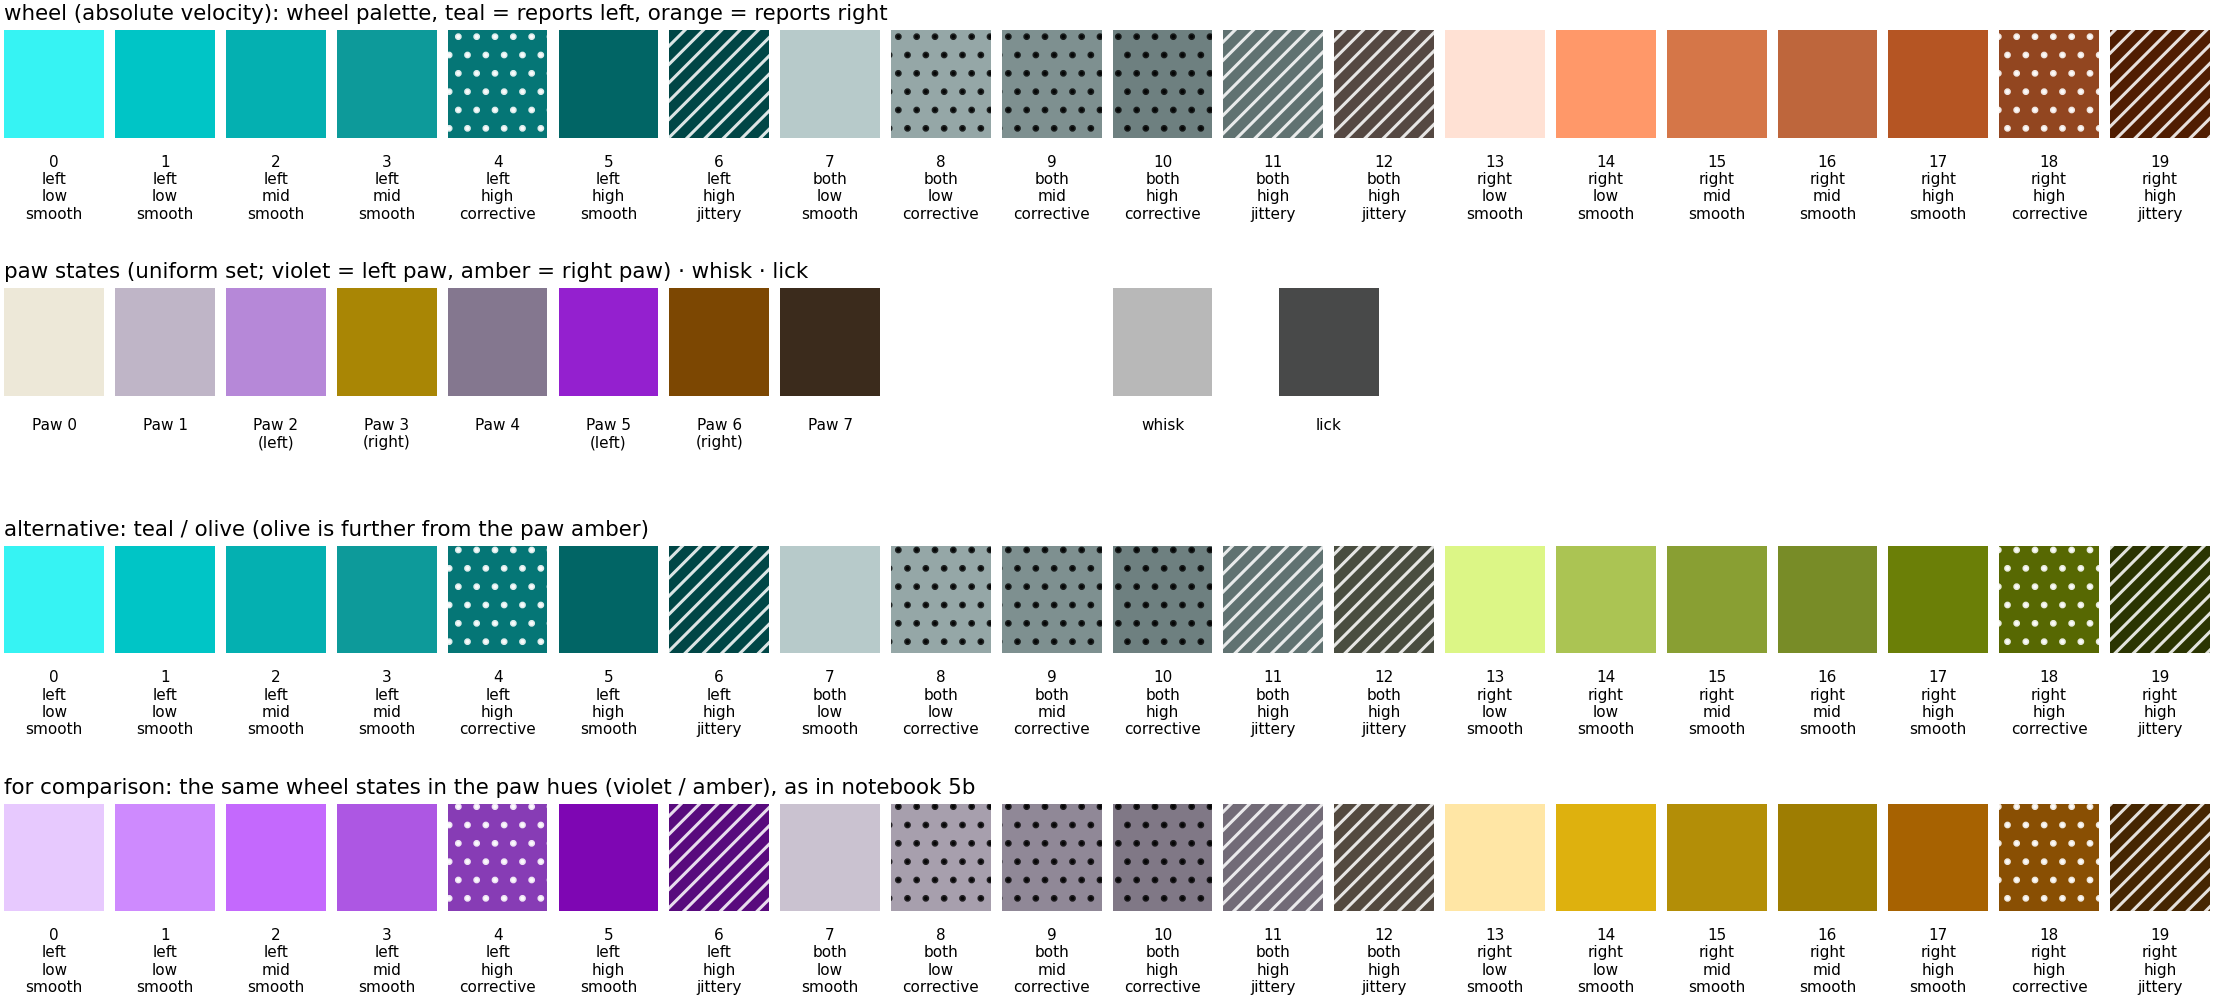

In [3]:
fig, axs = plt.subplots(4, 1, figsize=(13, 5.2), gridspec_kw=dict(hspace=1.4))
for ax, cols, title in [(axs[0], WCOL, 'wheel (absolute velocity): wheel palette, teal = reports left, orange = reports right'),
                        (axs[2], ALT_WCOL, 'alternative: teal / olive (olive is further from the paw amber)'),
                        (axs[3], OLD_WCOL, 'for comparison: the same wheel states in the paw hues (violet / amber), as in notebook 5b')]:
    for c in range(K):
        ax.add_patch(Rectangle((c, 0), .9, 1, facecolor=cols[c], hatch=WH[c], edgecolor=ps.hatch_ink(cols[c]), lw=0))
        ax.text(c + .45, -.15, f'{c}\n' + WDESC.label[c].replace(' ', '\n'), ha='center', va='top', fontsize=5)
    ax.set(xlim=(0, K), ylim=(0, 1)); ax.set_title(title, fontsize=7, loc='left')
for i, col in enumerate(ps.PAW_STATE_COLORS):
    axs[1].add_patch(Rectangle((i, 0), .9, 1, facecolor=col, lw=0))
    axs[1].text(i + .45, -.2, ps.paw_label(i).replace('  ', '\n'), ha='center', va='top', fontsize=5)
for j, (n, col) in enumerate([('whisk', ps.SYLLABLE['Whisk']), ('lick', ps.SYLLABLE['Lick'])]):
    axs[1].add_patch(Rectangle((10 + 1.5 * j, 0), .9, 1, facecolor=col, lw=0)); axs[1].text(10.45 + 1.5 * j, -.2, n, ha='center', va='top', fontsize=5)
axs[1].set(xlim=(0, 20), ylim=(0, 1)); axs[1].set_title('paw states (uniform set; violet = left paw, amber = right paw) · whisk · lick', fontsize=7, loc='left')
for ax in axs:
    ax.set(xticks=[], yticks=[])
    for sp in ax.spines.values(): sp.set_visible(False)

## How paw and wheel states map onto each other

Frame by frame (60 Hz) on 40 random cohort sessions, pooled. Wheel 'still' = frames outside any IBL movement.
- **P(paw | wheel)**: for each wheel state, which paw states the frames are in.
- **lift** = P(paw, wheel) / (P(paw) P(wheel)): > 1 = the pair co-occurs more than by chance (log2 colour scale).
- **NMI** between the two frame labellings, overall and per session (how much one tells about the other).

/tmp/ipykernel_219250/3755240952.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_sess = frames.groupby('eid').apply(lambda d: nmi(d.w, d.paw))


10,692,083 frames, 40 sessions; NMI(paw, wheel) pooled = 0.193, per session median 0.217 [0.178-0.287]


NMI(paw, wheel moving / still) = 0.239


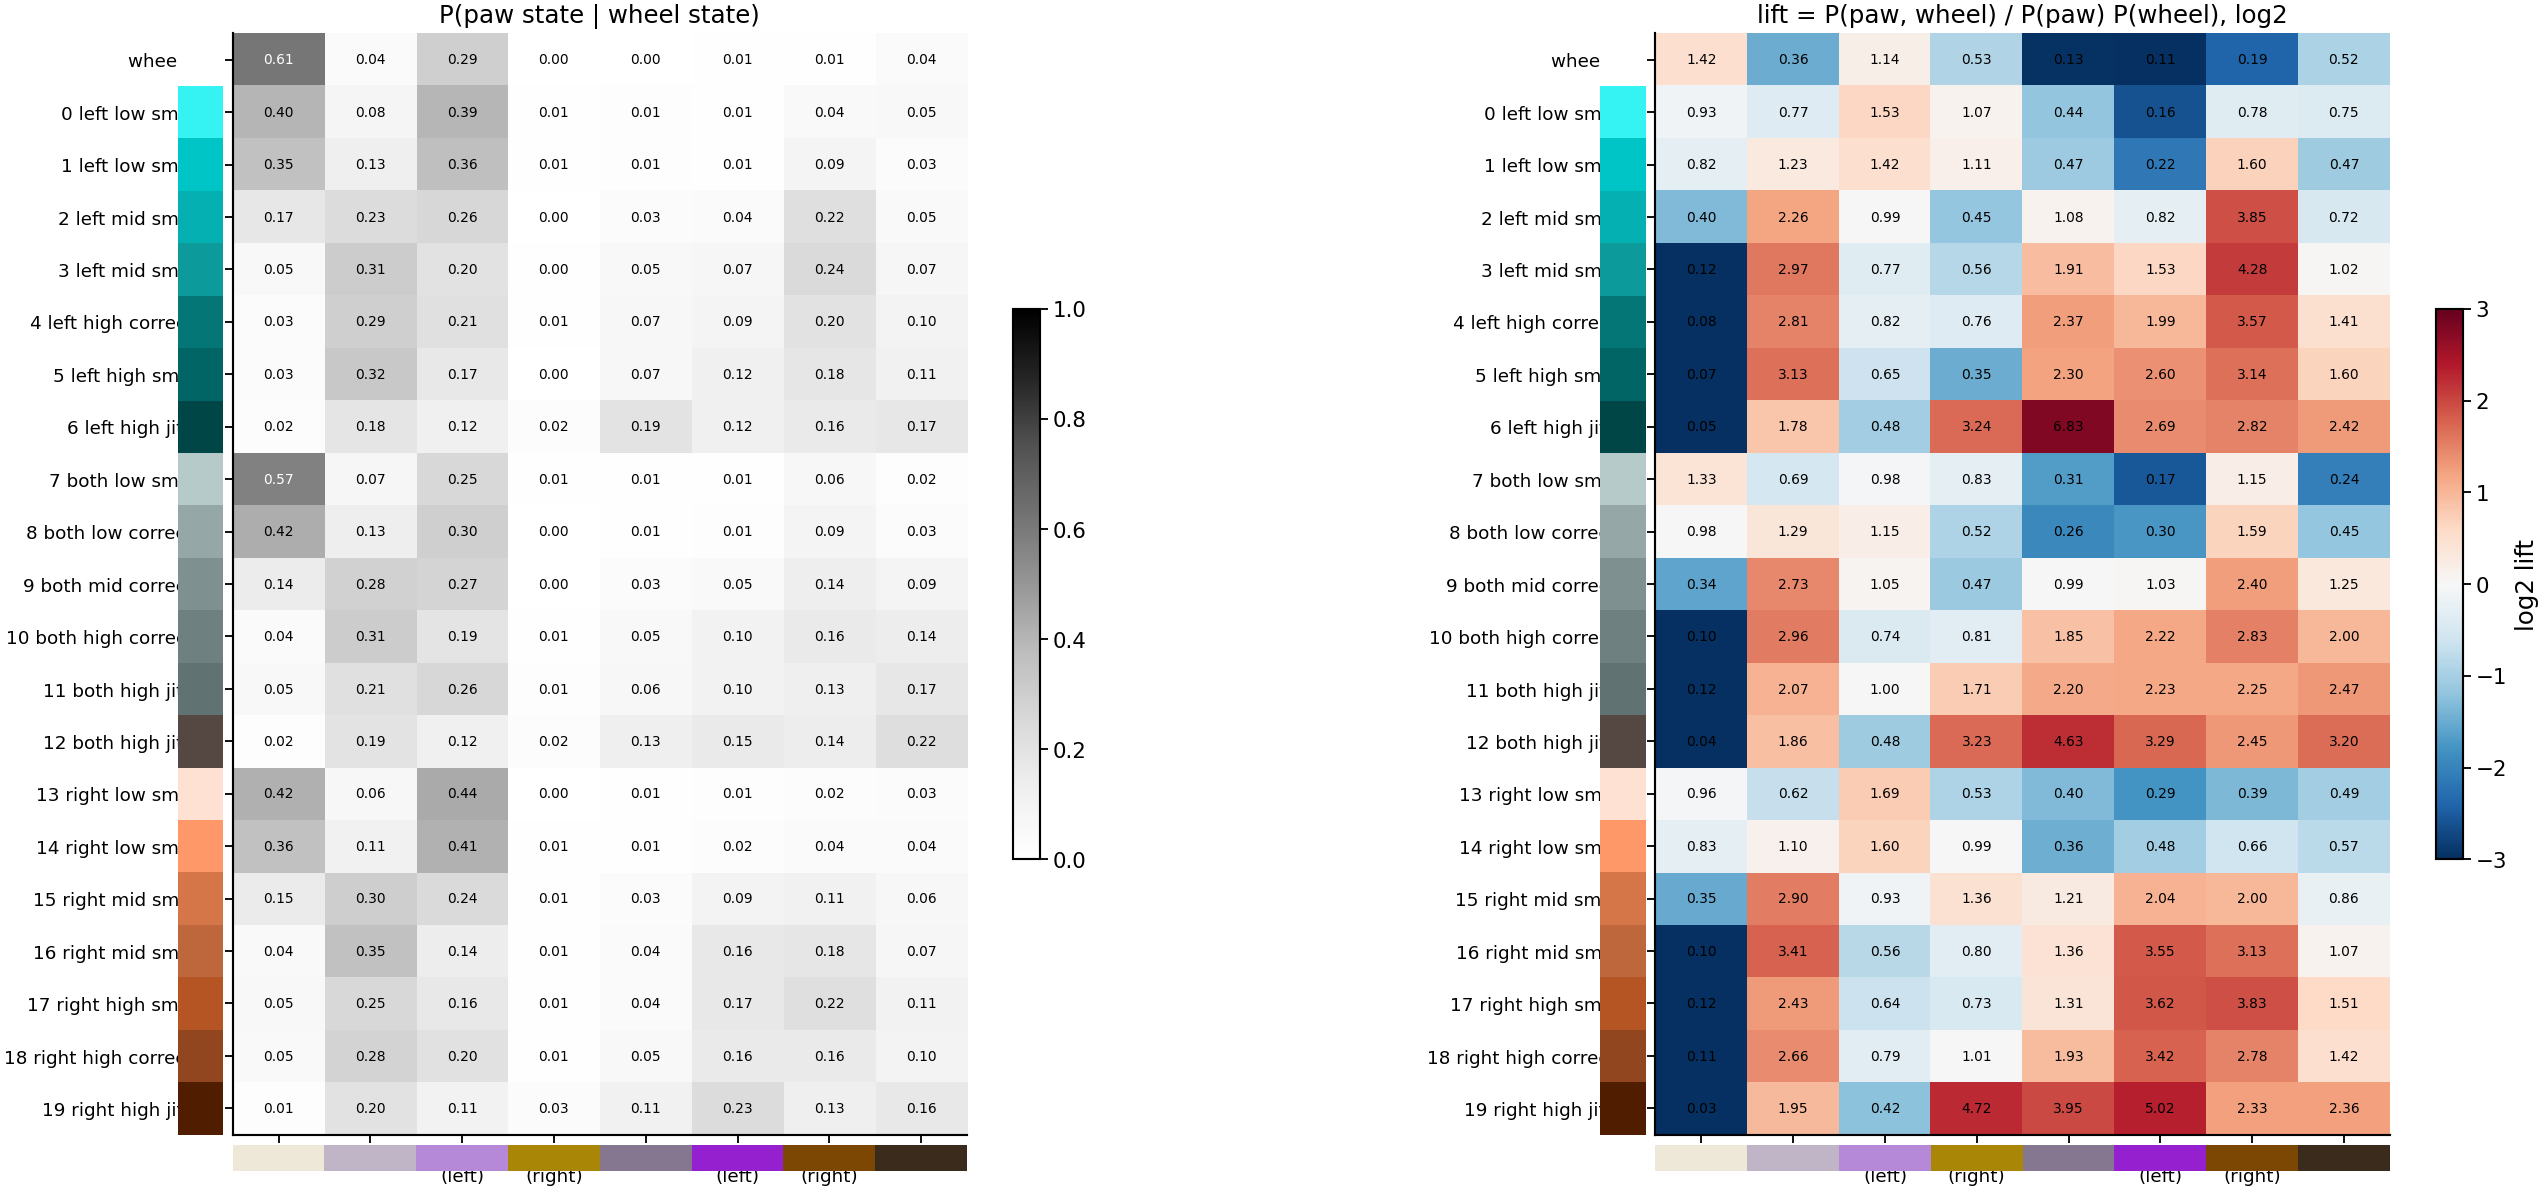

In [4]:
SAMPLE = coh.sample(40, random_state=0)
frames = pd.concat(Parallel(n_jobs=8)(delayed(lambda m, e: load(m, e)[0][['mouse', 'eid', 'paw', 'wheel']])(m, e)
                                      for m, e in zip(SAMPLE.mouse, SAMPLE.eid)), ignore_index=True)
frames = frames.dropna(subset=['paw'])
frames['paw'] = frames.paw.astype(int)
WN = ['wheel still'] + [f'{c} {WDESC.label[c]}' for c in range(K)]
frames['w'] = frames.wheel + 1                       # 0 = still, 1.. = cluster + 1
ct = pd.crosstab(frames.w, frames.paw).reindex(index=range(K + 1), columns=range(ps.N_PAW_STATES), fill_value=0)
p_paw_given_w = ct.div(ct.sum(1), axis=0)
joint = ct / ct.values.sum()
lift = joint / np.outer(joint.sum(1), joint.sum(0))
from sklearn.metrics import normalized_mutual_info_score as nmi
per_sess = frames.groupby('eid').apply(lambda d: nmi(d.w, d.paw))
print(f'{len(frames):,} frames, {frames.eid.nunique()} sessions; NMI(paw, wheel) pooled = {nmi(frames.w, frames.paw):.3f}, '
      f'per session median {per_sess.median():.3f} [{per_sess.quantile(.1):.3f}-{per_sess.quantile(.9):.3f}]')
print(f'NMI(paw, wheel moving / still) = {nmi(frames.w > 0, frames.paw):.3f}')

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw=dict(wspace=.55))
fig.subplots_adjust(left=.14)
im = axs[0].imshow(p_paw_given_w.values, cmap='Greys', vmin=0, vmax=1, aspect='auto')
axs[0].set_title('P(paw state | wheel state)', fontsize=8)
L = np.log2(lift.values.clip(1 / 8, 8))
im2 = axs[1].imshow(L, cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto')
axs[1].set_title('lift = P(paw, wheel) / P(paw) P(wheel), log2', fontsize=8)
for ax, M in zip(axs, [p_paw_given_w.values, lift.values]):
    ax.set_yticks(range(K + 1), WN, fontsize=6)
    ax.set_xticks(range(ps.N_PAW_STATES), [ps.paw_label(i).replace('  ', '\n') for i in range(ps.N_PAW_STATES)], fontsize=6)
    for tick, c in zip(ax.get_xticklabels(), ps.PAW_STATE_COLORS): tick.set_color('k')
    for i in range(K + 1):
        ax.add_patch(Rectangle((-1.1, i - .5), .5, 1, facecolor='white' if i == 0 else WCOL[i - 1], clip_on=False, lw=0))
    for j in range(ps.N_PAW_STATES):
        ax.add_patch(Rectangle((j - .5, K + .7), 1, .5, facecolor=ps.PAW_STATE_COLORS[j], clip_on=False, lw=0))
    for i in range(K + 1):
        for j in range(ps.N_PAW_STATES):
            ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=4.5,
                    color='w' if (ax is axs[0] and M[i, j] > .5) else 'k')
plt.colorbar(im, ax=axs[0], shrink=.5); plt.colorbar(im2, ax=axs[1], shrink=.5, label='log2 lift')

In [5]:
# the other direction: when the paw is in a given state, is the wheel moving, and how?
p_w_given_paw = ct.div(ct.sum(0), axis=1)
summary = pd.DataFrame({
    'fraction of frames': joint.sum(0).values,
    'P(wheel moving)': 1 - p_w_given_paw.loc[0].values,
    'most likely wheel state when moving': [WN[ct.iloc[1:, j].values.argmax() + 1] for j in range(ps.N_PAW_STATES)],
    'P(left-side wheel | moving)': [ct.iloc[1:, j][(WDESC.side == 'left').values].sum() / ct.iloc[1:, j].sum() for j in range(ps.N_PAW_STATES)],
    'P(right-side wheel | moving)': [ct.iloc[1:, j][(WDESC.side == 'right').values].sum() / ct.iloc[1:, j].sum() for j in range(ps.N_PAW_STATES)],
}, index=[ps.paw_label(i) for i in range(ps.N_PAW_STATES)])
summary.round(3)

,fraction of frames,P(wheel moving),most likely wheel state when moving,P(left-side wheel | moving),P(right-side wheel | moving)
Paw 0,0.431,0.045,11 both high jittery,0.212,0.311
Paw 1,0.104,0.760,12 both high jittery,0.217,0.363
Paw 2 (left),0.257,0.234,11 both high jittery,0.211,0.307
Paw 3 (right),0.007,0.642,19 right high jittery,0.143,0.413
Paw 4,0.028,0.914,12 both high jittery,0.247,0.299
Paw 5 (left),0.046,0.924,19 right high jittery,0.146,0.468
Paw 6 (right),0.056,0.872,12 both high jittery,0.257,0.338
Paw 7,0.070,0.649,12 both high jittery,0.161,0.285


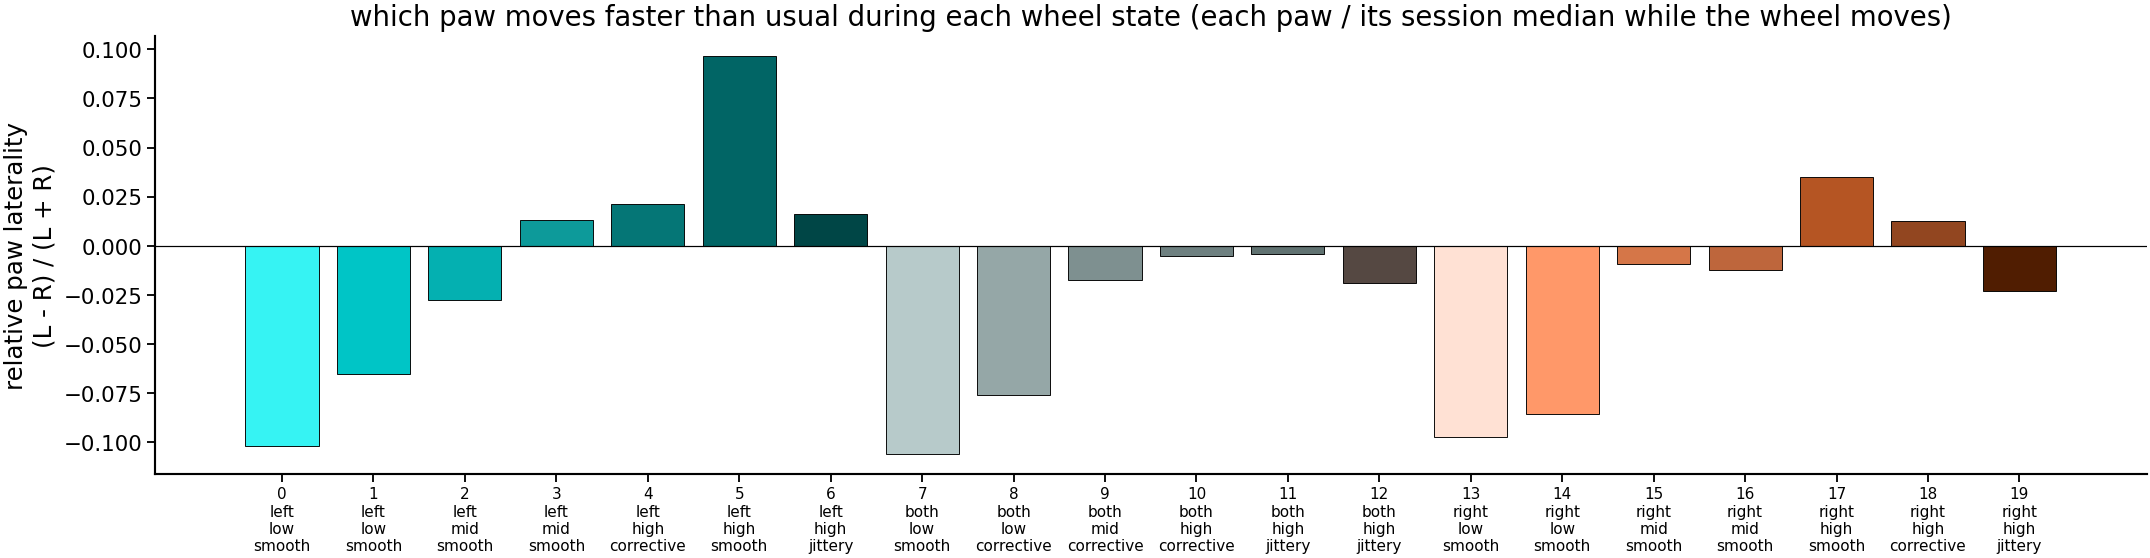

In [6]:
# paw speed during wheel movements: which paw moves more for left- vs right-reporting wheel states?
spd = pd.concat(Parallel(n_jobs=8)(delayed(lambda m, e: load(m, e)[0][['eid', 'wheel', 'l_speed', 'r_speed']])(m, e)
                                   for m, e in zip(SAMPLE.mouse, SAMPLE.eid)), ignore_index=True)
# the left paw is nearer the (left) camera and looks faster in px/s, so each paw's speed is divided by its own
# median speed during that session's wheel movements: laterality is then RELATIVE (0 = the session's usual balance)
spd = spd[spd.wheel >= 0].copy()
for p in ('l_speed', 'r_speed'):
    spd[p] = spd[p] / spd.groupby('eid')[p].transform('median')
g = spd.groupby('wheel')[['l_speed', 'r_speed']].median()
g['paw_laterality'] = (g.l_speed - g.r_speed) / (g.l_speed + g.r_speed)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(K), g.paw_laterality.reindex(range(K)), color=WCOL, hatch=None, edgecolor='k', lw=.3)
ax.axhline(0, c='k', lw=.4)
ax.set_xticks(range(K), [f'{c}\n' + WDESC.label[c].replace(' ', '\n') for c in range(K)], fontsize=5)
ax.set(ylabel='relative paw laterality\n(L - R) / (L + R)', title='which paw moves faster than usual during each wheel state (each paw / its session median while the wheel moves)')
plt.tight_layout()